# Analyse des accidents routiers en Australie-Méridionale avec PySpark
### Reproduction critique et enrichissement de l'étude de Rakesh Nain (2012–2019)

**Projet :** Big Data — notebook Jupyter / VS Code  


**Problématique.** Comment exploiter les abstractions de Spark (RDD, DataFrame et Spark SQL) pour étudier les accidents routiers, vérifier la fiabilité des résultats publiés et proposer des analyses complémentaires ?

**Notre démarche :**
1. Lire et contrôler les données de manière reproductible.
2. Refaire les questions de l'article original (RDD, DataFrame, Spark SQL).
3. Identifier les limites méthodologiques, notamment les jointures et les données manquantes.
4. Ajouter des analyses temporelles et contextuelles, des graphiques et une comparaison des approches.

## 0. Installation et organisation des fichiers

Dans VS Code, ouvrir ce fichier `.ipynb`, sélectionner un **interpréteur Python** contenant `pyspark`, `pandas`, `matplotlib` et `ipykernel`. Si besoin, exécuter **une seule fois** dans le terminal de VS Code :

```bash
python -m pip install pyspark pandas matplotlib ipykernel
```

Apache Spark nécessite également Java (une version compatible avec votre version de Spark : voir la [documentation officielle](https://spark.apache.org/docs/latest/)).

Disposition attendue :

```text
big data/
├── etude_accidents_pyspark.ipynb  ← ce notebook
├── crash_data/
│   ├── ...csv
│   └── ...csv
└── units_data/
    ├── ...csv
    └── ...csv
```

Le code cherche également ces deux répertoires **un niveau au-dessus** du notebook. Aucun chemin absolu spécifique à un ordinateur n'est nécessaire.

In [1]:
from pathlib import Path
from time import perf_counter
from statistics import median

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import SparkSession, functions as F

# Le dossier de travail est généralement celui où VS Code ouvre le notebook.
# Si les dossiers sont dans le répertoire parent, on le détecte également.
repertoires_possibles = [Path.cwd(), Path.cwd().parent]
BASE_DIR = next(
    (p for p in repertoires_possibles
     if (p / "crash_data").is_dir() and (p / "units_data").is_dir()),
    None,
)
if BASE_DIR is None:
    raise FileNotFoundError(
        "Dossiers 'crash_data' et 'units_data' introuvables. "
        f"Répertoire courant : {Path.cwd()}. "
        "Place les dossiers à côté du notebook ou dans son dossier parent."
    )

fichiers_crash = sorted((BASE_DIR / "crash_data").rglob("*.csv"))
fichiers_units = sorted((BASE_DIR / "units_data").rglob("*.csv"))
if not fichiers_crash or not fichiers_units:
    raise FileNotFoundError("Au moins un des deux dossiers ne contient aucun fichier .csv.")

print(f"Dossier du projet : {BASE_DIR.resolve()}")
print(f"Fichiers Crash : {len(fichiers_crash)}")
print(f"Fichiers Units : {len(fichiers_units)}")
print("Exemples :", fichiers_crash[0].name, "/", fichiers_units[0].name)

Dossier du projet : /home/omar/Bureau/5A/big data
Fichiers Crash : 8
Fichiers Units : 8
Exemples : 2012_DATA_SA_Crash.csv / 2012_DATA_SA_Units.csv


## 1. Initialisation de Spark

Nous utilisons Spark en **mode local** : les traitements sont parallélisés sur les cœurs de notre ordinateur. Le même programme peut être adapté à un cluster distribué. Le nombre de partitions observé dépend de la machine et de l'organisation des fichiers : il n'est pas censé être identique à celui de l'article.

In [2]:
# local[*] : Spark utilise les cœurs logiques disponibles sur cet ordinateur.
spark = (
    SparkSession.builder
    .appName("Etude_Critique_Road_Crash_South_Australia")
    .master("local[*]")
    # Les CSV sont locaux : ne pas utiliser le HDFS configuré globalement.
    .config("spark.hadoop.fs.defaultFS", "file:///")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark :", spark.version)
print("Mode :", spark.sparkContext.master)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/16 09:02:57 WARN Utils: Your hostname, omar-Latitude-3440, resolves to a loopback address: 127.0.1.1; using 10.188.134.164 instead (on interface wlp0s20f3)
26/10/16 09:02:57 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/10/16 09:02:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/10/16 09:03:00 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Spark : 4.2.0
Mode : local[*]


## 2. Chargement et première exploration

Les deux jeux de données ont des granularités différentes :

- `Crash` : une ligne pour un **événement d'accident** (`REPORT_ID`).
- `Units` : une ligne pour une **unité impliquée** (véhicule, piéton, etc.). Plusieurs unités peuvent correspondre au même accident.

La lecture CSV de Spark gère les séparateurs, l'en-tête et les guillemets. Elle évite la faiblesse de `line.split(',')` rencontré dans l'article : ce découpage manuel devient incorrect si une valeur contient une virgule entre guillemets.

In [3]:
# Lecture globale de tous les fichiers CSV de chaque dossier.
# inferSchema=False évite les inférences variables par fichier ;
# les conversions numériques seront effectuées explicitement ensuite.
options_csv = {"header": "true", "inferSchema": "false", "escape": '"', "mode": "PERMISSIVE"}
crash_raw = spark.read.options(**options_csv).csv([str(p) for p in fichiers_crash])
units_raw = spark.read.options(**options_csv).csv([str(p) for p in fichiers_units])

print("--- Crash ---")
crash_raw.printSchema()
crash_raw.show(3, truncate=False)
print("--- Units ---")
units_raw.printSchema()
units_raw.show(3, truncate=False)

--- Crash ---
root
 |-- REPORT_ID: string (nullable = true)
 |-- Stats Area: string (nullable = true)
 |-- Suburb: string (nullable = true)
 |-- Postcode: string (nullable = true)
 |-- LGA Name: string (nullable = true)
 |-- Total Units: string (nullable = true)
 |-- Total Cas: string (nullable = true)
 |-- Total Fats: string (nullable = true)
 |-- Total SI: string (nullable = true)
 |-- Total MI: string (nullable = true)
 |-- Year: string (nullable = true)
 |-- Month: string (nullable = true)
 |-- Day: string (nullable = true)
 |-- Time: string (nullable = true)
 |-- Area Speed: string (nullable = true)
 |-- Position Type: string (nullable = true)
 |-- Horizontal Align: string (nullable = true)
 |-- Vertical Align: string (nullable = true)
 |-- Other Feat: string (nullable = true)
 |-- Road Surface: string (nullable = true)
 |-- Moisture Cond: string (nullable = true)
 |-- Weather Cond: string (nullable = true)
 |-- DayNight: string (nullable = true)
 |-- Crash Type: string (nullable 

+-----------------+--------------+--------------+--------+----------------------------------+-----------+---------+----------+--------+--------+----+-------+---------+--------+----------+-------------+----------------+--------------+--------------------+------------+-------------+------------+--------+------------------+---------+------------+-------------+-------------+------------+--------------+----------+----------+--------------+
|REPORT_ID        |Stats Area    |Suburb        |Postcode|LGA Name                          |Total Units|Total Cas|Total Fats|Total SI|Total MI|Year|Month  |Day      |Time    |Area Speed|Position Type|Horizontal Align|Vertical Align|Other Feat          |Road Surface|Moisture Cond|Weather Cond|DayNight|Crash Type        |Unit Resp|Entity Code |CSEF Severity|Traffic Ctrls|DUI Involved|Drugs Involved|ACCLOC_X  |ACCLOC_Y  |UNIQUE_LOC    |
+-----------------+--------------+--------------+--------+----------------------------------+-----------+---------+-------

+-----------------+-------+---------+-------------+------------------+--------+-------------------+------+---+---------+-------------+--------------+----------+------------------------+----------------+--------+--------+----+
|REPORT_ID        |Unit No|No Of Cas|Veh Reg State|Unit Type         |Veh Year|Direction Of Travel|Sex   |Age|Lic State|Licence Class|Licence Type  |Towing    |Unit Movement           |Number Occupants|Postcode|Rollover|Fire|
+-----------------+-------+---------+-------------+------------------+--------+-------------------+------+---+---------+-------------+--------------+----------+------------------------+----------------+--------+--------+----+
|2012-1-21/08/2019|01     |0        |NULL         |Pedal Cycle       |NULL    |South West         |Male  |035|NULL     |NULL         |NULL          |NULL      |Straight Ahead          |001             |5074    |NULL    |NULL|
|2012-1-21/08/2019|02     |0        |SA           |Motor Cars - Sedan|2009    |North West       

In [4]:
# Colonnes nécessaires pour reproduire l'étude de 2021.
colonnes_crash = {
    "REPORT_ID", "Suburb", "Total Cas", "Total Fats", "Year", "Month",
    "Day", "Time", "Crash Type", "CSEF Severity", "DUI Involved",
    "Drugs Involved", "DayNight", "Weather Cond",
}
colonnes_units = {
    "REPORT_ID", "Lic State", "Unit Type", "Veh Year", "Sex", "Age",
    "Licence Type", "Licence Class", "No Of Cas",
}

for nom, df, attendues in [
    ("Crash", crash_raw, colonnes_crash), ("Units", units_raw, colonnes_units)
]:
    manque = sorted(attendues - set(df.columns))
    if manque:
        raise ValueError(
            f"Colonnes manquantes dans {nom} : {manque}. "
            f"Colonnes disponibles : {df.columns}"
        )
    print(f"{nom} : {len(df.columns)} colonnes, colonnes essentielles OK.")

Crash : 33 colonnes, colonnes essentielles OK.
Units : 18 colonnes, colonnes essentielles OK.


### 2.1. Typage explicite et valeurs spéciales

Dans ces fichiers, certains nombres inconnus sont codés par du texte (`XXX`, `XXXX`, etc.). Les remplacer par **0** fausserait les moyennes et les totaux. Nous ne convertissons en entier que les valeurs constituées de chiffres ; les autres sont représentées par `NULL`.

Nous conservons les colonnes portant leurs **noms originaux** pour faciliter la comparaison avec l'article.

In [5]:
def convertir_entiers(df, colonnes):
    """Convertit sans erreur les chaînes entières ; toute autre valeur devient NULL."""
    for nom in colonnes:
        valeur = F.trim(F.col(nom))
        df = df.withColumn(
            nom,
            F.when(valeur.rlike(r"^[0-9]+$"), valeur.cast("int"))
             .otherwise(F.lit(None).cast("int")),
        )
    return df

crash_df = convertir_entiers(crash_raw, ["Total Cas", "Total Fats", "Year"])
units_df = convertir_entiers(units_raw, ["Age", "Veh Year", "No Of Cas"])

# Les identifiants sont harmonisés avant toute jointure.
crash_df = crash_df.withColumn("REPORT_ID", F.trim(F.col("REPORT_ID")))
units_df = units_df.withColumn("REPORT_ID", F.trim(F.col("REPORT_ID")))

print("Lignes Crash :", crash_df.count())
print("Lignes Units :", units_df.count())
print("Partitions Crash / Units :", crash_df.rdd.getNumPartitions(), "/", units_df.rdd.getNumPartitions())

Lignes Crash : 127672


Lignes Units : 272591


Partitions Crash / Units : 9 / 9


### 2.2. Contrôles de qualité et de cardinalité

Avant toute analyse, vérifions les valeurs manquantes, les collisions d'identifiants et les unités sans correspondance. Un `REPORT_ID` répété dans `Units` est normal ; un `REPORT_ID` répété dans `Crash` mérite une vérification.

In [6]:
def audit_nulls(df, colonnes, total):
    """Nombre et pourcentage de NULL ou champs vides, calculés avec Spark."""
    exprs = []
    for c in colonnes:
        vide = F.col(c).isNull() | (F.trim(F.col(c).cast("string")) == "")
        exprs.append(F.sum(F.when(vide, 1).otherwise(0)).alias(c))
    valeurs = df.agg(*exprs).first().asDict()
    return pd.DataFrame([
        {"Colonne": c, "Manquants": int(valeurs[c]),
         "% manquants": round(100 * valeurs[c] / total, 2) if total else 0}
        for c in colonnes
    ]).sort_values("% manquants", ascending=False)

n_crash = crash_df.count()
n_units = units_df.count()
display(audit_nulls(crash_df, [
    "REPORT_ID", "Year", "Month", "Day", "Time", "Total Cas", "Total Fats",
    "CSEF Severity", "DUI Involved", "Drugs Involved"
], n_crash))
display(audit_nulls(units_df, [
    "REPORT_ID", "Sex", "Age", "Veh Year", "Licence Type", "Lic State"
], n_units))

,Colonne,Manquants,% manquants
9,Drugs Involved,125818,98.55
8,DUI Involved,123693,96.88
1,Year,0,0.00
0,REPORT_ID,0,0.00
2,Month,0,0.00
3,Day,0,0.00
5,Total Cas,0,0.00
4,Time,0,0.00
7,CSEF Severity,0,0.00
6,Total Fats,0,0.00


,Colonne,Manquants,% manquants
2,Age,55033,20.19
3,Veh Year,51277,18.81
5,Lic State,48766,17.89
4,Licence Type,48695,17.86
1,Sex,38175,14.00
0,REPORT_ID,0,0.00


In [7]:
crash_id_non_uniques = crash_df.groupBy("REPORT_ID").count().filter(F.col("count") > 1).count()
units_sans_crash = units_df.join(
    crash_df.select("REPORT_ID").distinct(), "REPORT_ID", "left_anti"
).count()
crash_sans_units = crash_df.join(
    units_df.select("REPORT_ID").distinct(), "REPORT_ID", "left_anti"
).count()

print("REPORT_ID non uniques dans Crash :", crash_id_non_uniques)
print("Unités sans accident correspondant :", units_sans_crash)
print("Accidents sans unité correspondante :", crash_sans_units)
if crash_id_non_uniques:
    print("ATTENTION : vérifier les identifiants répétés avant de considérer REPORT_ID comme clé unique.")
if units_sans_crash or crash_sans_units:
    print("Certaines jointures ne porteront que sur les accidents disposant des deux tables.")

REPORT_ID non uniques dans Crash : 0
Unités sans accident correspondant : 0
Accidents sans unité correspondante : 0


## 3. Reproduction : approche RDD

Un **RDD** est une collection distribuée et immuable. Nous partons des lignes déjà parsées correctement par Spark CSV, puis utilisons l'API `RDD` pour reproduire les manipulations de l'article. Cela préserve l'objectif pédagogique **sans réintroduire le découpage CSV fragile**.

### 3.1. Partitionnement selon l'état d'immatriculation

Comme dans l'article, une partition regroupe les unités immatriculées en Australie-Méridionale (`SA`) et l'autre les autres états ou valeurs inconnues. Pour compter les éléments, `mapPartitionsWithIndex` est préférable à `glom().collect()`, qui rapatrierait inutilement toutes les lignes en mémoire.

In [8]:
units_rdd = units_df.rdd
crash_rdd = crash_df.rdd

# RDD clé/valeur : clé = état d'immatriculation, valeur = 1 unité.
rdd_etats = units_rdd.map(lambda r: (r["Lic State"] or "INCONNU", 1))
rdd_partitions = rdd_etats.partitionBy(2, lambda etat: 0 if etat == "SA" else 1)
repartition = rdd_partitions.mapPartitionsWithIndex(
    lambda indice, it: [(indice, sum(1 for _ in it))]
).collect()
print("Répartition SA / autres :", sorted(repartition))
print("Total vérifié :", sum(n for _, n in repartition), "=", n_units)
assert sum(n for _, n in repartition) == n_units

Répartition SA / autres : [(0, 198646), (1, 73945)]
Total vérifié : 272591 = 272591


### 3.2. Âge moyen selon le sexe

L'auteur indique des âges moyens proches de **40,8 ans** pour les hommes et **40,08 ans** pour les femmes. Nous recalculons les moyennes avec `aggregateByKey`, plus approprié ici qu'un `groupByKey()` qui stocke toutes les valeurs d'un même groupe. Nous filtrons les âges manifestement invalides (1 à 110 ans inclus) et ne retenons que les catégories `Male` et `Female`.

**Limite :** `Units` n'est pas un fichier exclusivement consacré aux conducteurs. Nous parlons donc d'âges des **personnes renseignées au niveau des unités**, et pas d'âge de tous les conducteurs de la population.

In [9]:
rdd_sexe_age = (
    units_df.filter(
        F.col("Sex").isin("Male", "Female") & F.col("Age").between(1, 110)
    )
    .select("Sex", "Age").rdd
    .map(lambda r: (r["Sex"], int(r["Age"])))
)

# Accumulateur = (somme des âges, nombre de personnes).
resultat_age = rdd_sexe_age.aggregateByKey(
    (0, 0),
    lambda acc, age: (acc[0] + age, acc[1] + 1),
    lambda a, b: (a[0] + b[0], a[1] + b[1]),
).mapValues(lambda x: round(x[0] / x[1], 2)).collect()
print("Âge moyen par sexe :", sorted(resultat_age))

Âge moyen par sexe : [('Female', 40.08), ('Male', 40.8)]


### 3.3. Année de fabrication des véhicules extrêmes

L'article trouve notamment des véhicules datés de **1900**. Cela ne signifie pas nécessairement qu'ils ont réellement été fabriqués cette année : il peut s'agir d'une valeur conventionnelle ou erronée. Nous montrons les extrêmes enregistrés, puis examinons leur plausibilité.

In [10]:
rdd_annees = (
    units_df.filter(F.col("Veh Year").isNotNull())
    .select("Veh Year", "Lic State", "Unit Type").rdd
    .map(lambda r: (r["Veh Year"], r["Lic State"], r["Unit Type"]))
)
print("5 plus anciennes valeurs :", rdd_annees.takeOrdered(5, key=lambda r: r[0]))
print("5 plus récentes valeurs :", rdd_annees.takeOrdered(5, key=lambda r: -r[0]))

annees_aberrantes = units_df.filter(
    F.col("Veh Year").isNotNull() & ~F.col("Veh Year").between(1900, 2019)
).count()
print("Années véhicule hors intervalle indicatif 1900–2019 :", annees_aberrantes)
# L'intervalle est un contrôle descriptif, pas une règle générale de nettoyage.

5 plus anciennes valeurs : [(1900, 'SA', 'Motor Cycle'), (1900, 'UNKNOWN', 'Motor Cycle'), (1900, 'SA', 'Motor Cycle'), (1900, 'VIC', 'Motor Cycle'), (1900, 'SA', 'Motor Cycle')]


5 plus récentes valeurs : [(2019, 'SA', 'Station Wagon'), (2019, 'SA', 'OMNIBUS'), (2019, 'SA', 'Motor Cars - Sedan'), (2019, 'NSW', 'Station Wagon'), (2019, 'VIC', 'SEMI TRAILER')]


Années véhicule hors intervalle indicatif 1900–2019 : 0


## 4. Reproduction : DataFrame API

Les DataFrames Spark permettent des opérations déclaratives (filtrer, agréger, joindre). Spark peut optimiser les plans d'exécution via son moteur SQL. Les calculs restent distribués ; nous ne récupérons sur le pilote que de petits tableaux agrégés.

### 4.1. Accidents à Adélaïde impliquant plus de trois victimes

In [11]:
adelaide = crash_df.filter(F.upper(F.trim(F.col("Suburb"))) == "ADELAIDE")
adelaide_grave = adelaide.filter(F.col("Total Cas") > 3)
print("Accidents correspondants :", adelaide_grave.count())
adelaide_grave.select(
    "REPORT_ID", "Year", "Month", "Day", "Time", "Total Cas", "Crash Type"
).orderBy(F.desc("Total Cas")).show(20, truncate=False)

Accidents correspondants : 6


+---------------------+----+--------+--------+--------+---------+--------------+
|REPORT_ID            |Year|Month   |Day     |Time    |Total Cas|Crash Type    |
+---------------------+----+--------+--------+--------+---------+--------------+
|2019-10404-8/07/2020 |2019|October |Monday  |08:20 am|6        |Right Turn    |
|2017-12182-15/08/2019|2017|December|Saturday|04:08 pm|5        |Hit Pedestrian|
|2018-601-17/01/2020  |2018|January |Sunday  |09:12 pm|4        |Hit Pedestrian|
|2017-1613-15/08/2019 |2017|February|Saturday|04:00 pm|4        |Right Turn    |
|2012-4842-21/08/2019 |2012|March   |Thursday|04:00 pm|4        |Rear End      |
|2012-5769-21/08/2019 |2012|March   |Friday  |09:30 am|4        |Right Angle   |
+---------------------+----+--------+--------+--------+---------+--------------+



### 4.2. Les dix accidents ayant le plus de victimes

`Total Cas` compte les victimes de l'accident (selon la définition du jeu de données). Attention : les dates ne comportent **pas de jour numérique exact** ; le champ `Day` correspond au jour de la semaine. Nous n'en déduisons jamais une date civile complète.

In [12]:
crash_df.select(
    "REPORT_ID", "Suburb", "Year", "Month", "Day", "Time", "Total Cas", "Total Fats"
).orderBy(F.desc_nulls_last("Total Cas")).show(10, truncate=False)

+---------------------+-------------+----+--------+---------+--------+---------+----------+
|REPORT_ID            |Suburb       |Year|Month   |Day      |Time    |Total Cas|Total Fats|
+---------------------+-------------+----+--------+---------+--------+---------+----------+
|2017-288-15/08/2019  |PARA HILLS   |2017|January |Wednesday|01:13 pm|11       |0         |
|2019-11734-8/07/2020 |STURT        |2019|November|Sunday   |07:25 pm|9        |0         |
|2016-3035-15/08/2019 |HACKHAM      |2016|January |Saturday |11:50 am|9        |3         |
|2016-6630-15/08/2019 |KANGAROO FLAT|2016|April   |Wednesday|09:00 pm|9        |0         |
|2014-9004-21/08/2019 |APY          |2014|July    |Friday   |07:20 pm|9        |1         |
|2014-14065-21/08/2019|MODBURY NORTH|2014|November|Tuesday  |03:09 pm|9        |0         |
|2016-7073-15/08/2019 |MERRITON     |2016|April   |Sunday   |12:35 pm|8        |4         |
|2016-14407-15/08/2019|STOCKWELL    |2016|October |Sunday   |03:46 pm|8        |

### 4.3. Nombre total de décès par type d'accident

On additionne `Total Fats` (**décès**) et non le nombre d'accidents. Pour distinguer fréquence et gravité, nous ajoutons une colonne comptant les événements.

+--------------------------+---------+-----+
|Crash Type                |Accidents|Deces|
+--------------------------+---------+-----+
|Hit Fixed Object          |19365    |245  |
|Head On                   |2086     |136  |
|Hit Pedestrian            |2848     |109  |
|Roll Over                 |5304     |93   |
|Right Angle               |24236    |82   |
|Rear End                  |37218    |33   |
|Side Swipe                |13111    |30   |
|Right Turn                |10083    |26   |
|Hit Parked Vehicle        |9148     |10   |
|Hit Animal                |2042     |7    |
|Other                     |739      |5    |
|Left Road - Out of Control|999      |3    |
|Hit Object on Road        |493      |2    |
+--------------------------+---------+-----+



/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


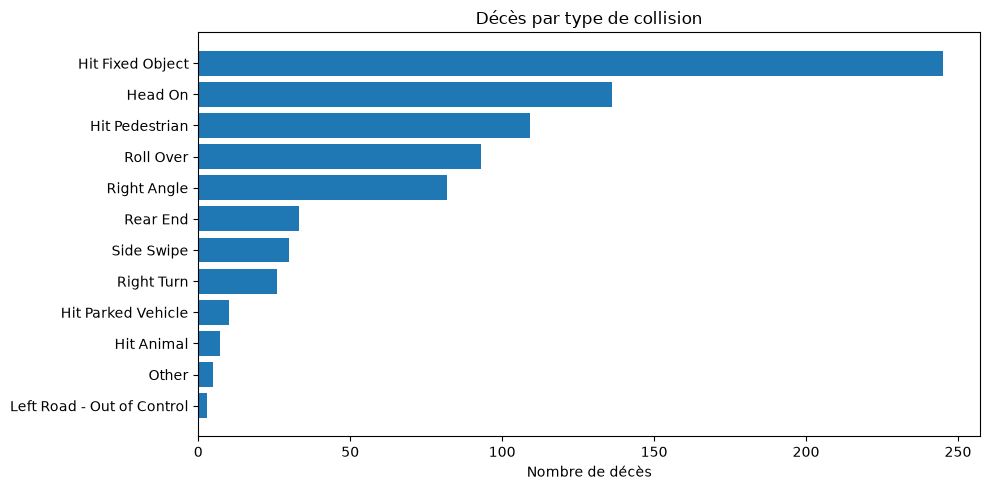

In [13]:
par_type = (
    crash_df.groupBy("Crash Type")
    .agg(
        F.count("REPORT_ID").alias("Accidents"),
        F.sum("Total Fats").alias("Deces"),
    )
    .orderBy(F.desc("Deces"))
)
par_type.show(20, truncate=False)

pdf_type = par_type.limit(12).toPandas()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(pdf_type["Crash Type"][::-1], pdf_type["Deces"][::-1])
ax.set(title="Décès par type de collision", xlabel="Nombre de décès")
plt.tight_layout()
plt.show()

### 4.4. Victimes dans les accidents impliquant au moins une unité sans permis

**Point méthodologique clé.** L'article joint `Crash` à `Units`, filtre `Licence Type = 'Unlicenced'` et somme `Total Cas`. Or, un accident peut compter plusieurs unités sans permis : sa valeur `Total Cas` risque alors d'être additionnée **plusieurs fois**.

Notre correction : extraire les identifiants **distincts** des accidents concernés et faire un `left_semi join`. Ainsi, les victimes sont comptabilisées une seule fois **par accident**. Cela ne démontre pas que le conducteur sans permis a causé ces victimes.

In [14]:
# La source utilise l'orthographe 'Unlicenced'. On accepte aussi 'Unlicensed'.
filtre_sans_permis = F.lower(F.trim(F.col("Licence Type"))).rlike(r"unlicen[cs]ed")
accidents_sans_permis = (
    units_df.filter(filtre_sans_permis).select("REPORT_ID").distinct()
)

# Reproduction du calcul naïf pour identifier un éventuel surcomptage.
naif = (
    crash_df.join(units_df.filter(filtre_sans_permis).select("REPORT_ID"), "REPORT_ID", "inner")
    .groupBy("Suburb")
    .agg(F.sum("Total Cas").alias("Victimes_naif"))
)

# Calcul corrigé : un accident figure une seule fois, même avec plusieurs unités.
crash_sans_permis = crash_df.join(accidents_sans_permis, "REPORT_ID", "left_semi")
corrige = (
    crash_sans_permis.groupBy("Suburb")
    .agg(F.sum("Total Cas").alias("Victimes_corrige"))
    .orderBy(F.desc("Victimes_corrige"), F.asc("Suburb"))
)

corrige.show(15, truncate=False)
comparaison_permis = (
    naif.join(corrige, "Suburb", "full_outer")
    .na.fill(0, subset=["Victimes_naif", "Victimes_corrige"])
    .withColumn("Surcomptage", F.col("Victimes_naif") - F.col("Victimes_corrige"))
)
comparaison_permis.orderBy(F.desc("Surcomptage")).show(10, truncate=False)

+---------------+----------------+
|Suburb         |Victimes_corrige|
+---------------+----------------+
|ADELAIDE       |42              |
|SALISBURY      |30              |
|PROSPECT       |27              |
|INGLE FARM     |22              |
|MORPHETT VALE  |20              |
|DRY CREEK      |19              |
|MURRAY BRIDGE  |19              |
|SALISBURY EAST |19              |
|MAWSON LAKES   |17              |
|NORTH ADELAIDE |17              |
|ENFIELD        |16              |
|GEPPS CROSS    |15              |
|REGENCY PARK   |15              |
|SALISBURY DOWNS|15              |
|ELIZABETH PARK |14              |
+---------------+----------------+
only showing top 15 rows


+------------------+-------------+----------------+-----------+
|Suburb            |Victimes_naif|Victimes_corrige|Surcomptage|
+------------------+-------------+----------------+-----------+
|BAUDIN BEACH      |4            |2               |2          |
|FITZROY           |4            |2               |2          |
|ONKAPARINGA HILLS |8            |6               |2          |
|COMMISSARIAT POINT|2            |1               |1          |
|EDWARDSTOWN       |8            |7               |1          |
|SALISBURY EAST    |20           |19              |1          |
|FERRYDEN PARK     |5            |4               |1          |
|GLOBE DERBY PARK  |3            |2               |1          |
|MELROSE PARK      |8            |7               |1          |
|FINDON            |6            |5               |1          |
+------------------+-------------+----------------+-----------+
only showing top 10 rows


### 4.5. Répartition des accidents selon leur gravité

Le champ `CSEF Severity` code quatre groupes dans cette version du jeu de données :

- **1: PDO** : dommage matériel seulement (*Property Damage Only*).
- **2: MI** : blessure légère (*Minor Injury*).
- **3: SI** : blessure grave (*Serious Injury*).
- **4: Fatal** : accident mortel.

Le nombre d'**accidents mortels** n'est pas le nombre de **personnes décédées** (`Total Fats`).

In [15]:
par_gravite = (
    crash_df.groupBy("CSEF Severity")
    .agg(F.count("REPORT_ID").alias("Accidents"))
    .withColumn(
        "Pourcentage",
        F.round(100 * F.col("Accidents") / F.lit(n_crash), 2)
    )
    .orderBy("CSEF Severity")
)
par_gravite.show(truncate=False)

+-------------+---------+-----------+
|CSEF Severity|Accidents|Pourcentage|
+-------------+---------+-----------+
|1: PDO       |84775    |66.4       |
|2: MI        |37300    |29.22      |
|3: SI        |4875     |3.82       |
|4: Fatal     |722      |0.57       |
+-------------+---------+-----------+



### 4.6. Alcool, drogues et gravité

Nous retrouvons les quatre cas étudiés par l'auteur, mais **les groupes « alcool signalé » et « drogues signalées » peuvent se chevaucher**. Son groupe « ni alcool ni drogues », construit à partir de `NULL`, représente en réalité des événements **sans marqueur positif renseigné**, pas nécessairement des dépistages négatifs.

Pour obtenir un graphique interprétable, nous construisons **quatre catégories exclusives** : les deux signalés, alcool seul signalé, drogues seules signalées, aucun marqueur positif signalé. La dernière catégorie **n'est pas** étiquetée « sobre ».

/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


CSEF Severity,1: PDO,2: MI,3: SI,4: Fatal
Marqueurs,,,,
Alcool + drogues signalés,12.08,50.67,24.16,13.09
Alcool signalé seul,57.27,29.67,10.43,2.64
Aucun marqueur positif signalé,67.49,28.74,3.36,0.42
Drogues signalées seules,12.92,61.57,20.50,5.01


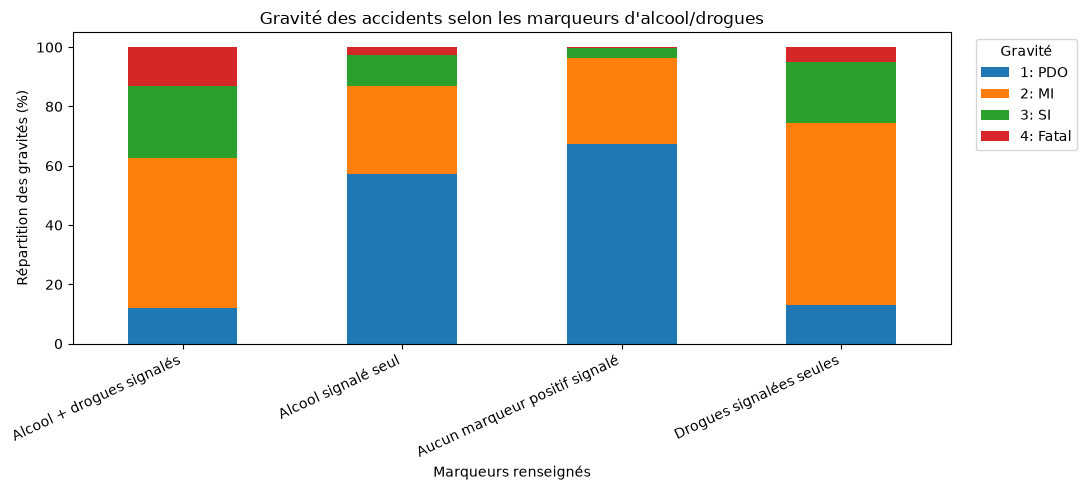

In [16]:
alcool_y = F.upper(F.trim(F.col("DUI Involved"))) == "Y"
drogues_y = F.upper(F.trim(F.col("Drugs Involved"))) == "Y"

avec_exposition = crash_df.withColumn(
    "Marqueurs",
    F.when(alcool_y & drogues_y, "Alcool + drogues signalés")
     .when(alcool_y, "Alcool signalé seul")
     .when(drogues_y, "Drogues signalées seules")
     .otherwise("Aucun marqueur positif signalé")
)

# Pour chaque catégorie, la distribution est normalisée PAR catégorie.
comptage_expo = (
    avec_exposition.groupBy("Marqueurs", "CSEF Severity")
    .agg(F.count("REPORT_ID").alias("Accidents"))
)
expo_pd = comptage_expo.toPandas()  # 4 × 4 lignes maximum
pivot = expo_pd.pivot_table(
    index="Marqueurs", columns="CSEF Severity",
    values="Accidents", aggfunc="sum", fill_value=0
)
pivot = pivot.reindex(columns=sorted(pivot.columns))
pourc = pivot.div(pivot.sum(axis=1), axis=0).mul(100)
display(pourc.round(2))

ax = pourc.plot(kind="bar", stacked=True, figsize=(11, 5))
ax.set(title="Gravité des accidents selon les marqueurs d'alcool/drogues",
       xlabel="Marqueurs renseignés", ylabel="Répartition des gravités (%)")
ax.legend(title="Gravité", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [17]:
# Reproduisons explicitement les quatre dénominateurs (CHEVAUCHEMENT des groupes).
# 'Aucun Y' n'implique pas un test négatif : l'absence de données est possible.
scenarios = {
    "Drogues signalées": drogues_y,
    "Alcool signalé": alcool_y,
    "Alcool ET drogues signalés": alcool_y & drogues_y,
    "Aucun Y signalé": (~F.coalesce(alcool_y, F.lit(False))) &
                       (~F.coalesce(drogues_y, F.lit(False))),
}
for nom, filtre in scenarios.items():
    resultat = (crash_df.filter(filtre).groupBy("CSEF Severity")
                .count().orderBy("CSEF Severity").collect())
    total_scenario = sum(r["count"] for r in resultat)
    print(f"\n{nom} : {total_scenario} accidents")
    for r in resultat:
        pourcentage = 100 * r["count"] / total_scenario if total_scenario else 0
        print(f"  {r['CSEF Severity']}: {r['count']} ({pourcentage:.2f} %)")


Drogues signalées : 1854 accidents
  1: PDO: 237 (12.78 %)
  2: MI: 1109 (59.82 %)
  3: SI: 391 (21.09 %)
  4: Fatal: 117 (6.31 %)



Alcool signalé : 3979 accidents
  1: PDO: 2144 (53.88 %)
  2: MI: 1243 (31.24 %)
  3: SI: 456 (11.46 %)
  4: Fatal: 136 (3.42 %)



Alcool ET drogues signalés : 298 accidents
  1: PDO: 36 (12.08 %)
  2: MI: 151 (50.67 %)
  3: SI: 72 (24.16 %)
  4: Fatal: 39 (13.09 %)



Aucun Y signalé : 122137 accidents
  1: PDO: 82430 (67.49 %)
  2: MI: 35099 (28.74 %)
  3: SI: 4100 (3.36 %)
  4: Fatal: 508 (0.42 %)


## 5. Une même question avec RDD, DataFrame et Spark SQL

L'article montre qu'une requête peut être exprimée par les trois interfaces. Pour une comparaison honnête, nous imposons **les mêmes colonnes, conditions et granularités**.

**Question A :** pour les unités impliquées dans les accidents d'Adélaïde, obtenir l'identifiant, la date partielle (`année-mois-jour de semaine`), l'heure, les victimes **au niveau accident**, le sexe, l'âge et le type de permis **au niveau unité**.

> Attention : `Total Cas` est répété sur plusieurs lignes si plusieurs unités participent au même accident. **On ne somme pas cette colonne après la jointure.**

In [18]:
# -- Variante DataFrame --
question_a_df = (
    crash_df.alias("c")
    .join(units_df.alias("u"), "REPORT_ID", "inner")
    .filter(F.upper(F.trim(F.col("c.Suburb"))) == "ADELAIDE")
    .select(
        F.col("REPORT_ID"),
        F.concat_ws("-", F.col("c.Year"), F.col("c.Month"), F.col("c.Day")).alias("Date_partielle"),
        F.col("c.Time").alias("Heure"),
        F.col("c.Total Cas").alias("Victimes_accident"),
        F.col("u.Sex"), F.col("u.Age"), F.col("u.Licence Type"),
    )
)
question_a_df.show(10, truncate=False)

+------------------+---------------------+--------+-----------------+------+----+--------------+
|REPORT_ID         |Date_partielle       |Heure   |Victimes_accident|Sex   |Age |Licence Type  |
+------------------+---------------------+--------+-----------------+------+----+--------------+
|2012-27-21/08/2019|2012-January-Monday  |08:45 am|0                |Male  |84  |Full          |
|2012-27-21/08/2019|2012-January-Monday  |08:45 am|0                |Male  |40  |Full          |
|2012-32-21/08/2019|2012-January-Friday  |05:45 pm|0                |Male  |47  |Full          |
|2012-32-21/08/2019|2012-January-Friday  |05:45 pm|0                |Male  |NULL|NULL          |
|2012-42-21/08/2019|2012-January-Friday  |07:30 pm|1                |Female|18  |Provisional 2 |
|2012-42-21/08/2019|2012-January-Friday  |07:30 pm|1                |Male  |20  |Full          |
|2012-43-21/08/2019|2012-January-Saturday|08:00 am|0                |Female|24  |Provisional 1 |
|2012-43-21/08/2019|2012-Janua

In [19]:
# -- Variante Spark SQL --
crash_df.createOrReplaceTempView("crashes")
units_df.createOrReplaceTempView("units")

question_a_sql = spark.sql("""
    SELECT c.REPORT_ID,
           CONCAT_WS('-', CAST(c.Year AS STRING), c.Month, c.Day) AS Date_partielle,
           c.Time AS Heure,
           c.`Total Cas` AS Victimes_accident,
           u.Sex, u.Age, u.`Licence Type`
    FROM crashes c
    JOIN units u ON c.REPORT_ID = u.REPORT_ID
    WHERE UPPER(TRIM(c.Suburb)) = 'ADELAIDE'
""")
question_a_sql.show(10, truncate=False)

+------------------+---------------------+--------+-----------------+------+----+--------------+
|REPORT_ID         |Date_partielle       |Heure   |Victimes_accident|Sex   |Age |Licence Type  |
+------------------+---------------------+--------+-----------------+------+----+--------------+
|2012-27-21/08/2019|2012-January-Monday  |08:45 am|0                |Male  |84  |Full          |
|2012-27-21/08/2019|2012-January-Monday  |08:45 am|0                |Male  |40  |Full          |
|2012-32-21/08/2019|2012-January-Friday  |05:45 pm|0                |Male  |47  |Full          |
|2012-32-21/08/2019|2012-January-Friday  |05:45 pm|0                |Male  |NULL|NULL          |
|2012-42-21/08/2019|2012-January-Friday  |07:30 pm|1                |Female|18  |Provisional 2 |
|2012-42-21/08/2019|2012-January-Friday  |07:30 pm|1                |Male  |20  |Full          |
|2012-43-21/08/2019|2012-January-Saturday|08:00 am|0                |Female|24  |Provisional 1 |
|2012-43-21/08/2019|2012-Janua

In [20]:
# -- Variante RDD (depuis des CSV déjà correctement parsés) --
crash_adelaide_rdd = (
    crash_df.filter(F.upper(F.trim(F.col("Suburb"))) == "ADELAIDE")
    .select("REPORT_ID", "Year", "Month", "Day", "Time", "Total Cas")
    .rdd.map(lambda r: (
        r["REPORT_ID"],
        ("-".join(str(r[k]) for k in ["Year", "Month", "Day"] if r[k] is not None),
         r["Time"], r["Total Cas"])
    ))
)
units_detail_rdd = (
    units_df.select("REPORT_ID", "Sex", "Age", "Licence Type")
    .rdd.map(lambda r: (r["REPORT_ID"], (r["Sex"], r["Age"], r["Licence Type"])))
)
question_a_rdd = crash_adelaide_rdd.join(units_detail_rdd)
print("Exemple RDD :", question_a_rdd.take(5))

# Contrôle simple : nombre de lignes de jointure identique pour 3 APIs.
nb_a_rdd = question_a_rdd.count()
nb_a_df = question_a_df.count()
nb_a_sql = question_a_sql.count()
print("Nombres de lignes RDD / DataFrame / SQL :", nb_a_rdd, nb_a_df, nb_a_sql)
assert nb_a_rdd == nb_a_df == nb_a_sql, "Incohérence entre les trois méthodes"

Exemple RDD : [('2012-75-21/08/2019', (('2012-February-Thursday', '07:45 pm', 0), ('Male', 46, None))), ('2012-75-21/08/2019', (('2012-February-Thursday', '07:45 pm', 0), ('Male', 22, 'Full'))), ('2012-259-21/08/2019', (('2012-May-Friday', '05:00 pm', 0), ('Male', 27, 'Full'))), ('2012-259-21/08/2019', (('2012-May-Friday', '05:00 pm', 0), ('Male', 31, 'Full'))), ('2012-520-21/08/2019', (('2012-November-Friday', '02:40 pm', 1), ('Female', 55, 'Full')))]


Nombres de lignes RDD / DataFrame / SQL : 11965 11965 11965


### 5.2. Question B : victimes par banlieue avec au moins une unité sans permis

Cette seconde requête reproduit l'intention de l'article **avec une définition cohérente**, identique dans les trois interfaces. Nous ne confondons plus « absence de permis » et « permis renseigné » (conditions qui n'ont pas la même signification).

In [21]:
# -- RDD : jointure avec les identifiants distincts des accidents concernés --
rdd_ids_sans_permis = (
    units_df.filter(filtre_sans_permis).select("REPORT_ID").distinct()
    .rdd.map(lambda r: (r["REPORT_ID"], 1))
)
rdd_accidents_suburb = (
    crash_df.select("REPORT_ID", "Suburb", "Total Cas")
    .rdd.map(lambda r: (r["REPORT_ID"], (r["Suburb"], r["Total Cas"] or 0)))
)
question_b_rdd = (
    rdd_accidents_suburb.join(rdd_ids_sans_permis)
    .map(lambda p: (p[1][0][0], p[1][0][1]))
    .reduceByKey(lambda a, b: a + b)
)
print("RDD - top 10 :", question_b_rdd.takeOrdered(10, key=lambda p: -p[1]))

# -- DataFrame : le calcul corrigé 'corrige' existe déjà en section 4.4 --
print("DataFrame - top 10 :")
corrige.show(10, truncate=False)

# -- Spark SQL : IN agit comme un filtrage par ensemble d'identifiants --
question_b_sql = spark.sql("""
    SELECT Suburb, SUM(`Total Cas`) AS Victimes
    FROM crashes
    WHERE REPORT_ID IN (
        SELECT DISTINCT REPORT_ID FROM units
        WHERE LOWER(TRIM(`Licence Type`)) RLIKE 'unlicen[cs]ed'
    )
    GROUP BY Suburb
    ORDER BY Victimes DESC, Suburb
""")
print("Spark SQL - top 10 :")
question_b_sql.show(10, truncate=False)

# Le total doit être identique pour les trois expressions.
total_rdd = sum(v for _, v in question_b_rdd.collect())
total_df = corrige.agg(F.sum("Victimes_corrige")).first()[0] or 0
total_sql = question_b_sql.agg(F.sum("Victimes")).first()[0] or 0
print("Totaux RDD / DF / SQL :", total_rdd, total_df, total_sql)
assert total_rdd == total_df == total_sql, "Les agrégats divergent"

RDD - top 10 : [('ADELAIDE', 42), ('SALISBURY', 30), ('PROSPECT', 27), ('INGLE FARM', 22), ('MORPHETT VALE', 20), ('SALISBURY EAST', 19), ('DRY CREEK', 19), ('MURRAY BRIDGE', 19), ('MAWSON LAKES', 17), ('NORTH ADELAIDE', 17)]
DataFrame - top 10 :


+--------------+----------------+
|Suburb        |Victimes_corrige|
+--------------+----------------+
|ADELAIDE      |42              |
|SALISBURY     |30              |
|PROSPECT      |27              |
|INGLE FARM    |22              |
|MORPHETT VALE |20              |
|DRY CREEK     |19              |
|MURRAY BRIDGE |19              |
|SALISBURY EAST|19              |
|MAWSON LAKES  |17              |
|NORTH ADELAIDE|17              |
+--------------+----------------+
only showing top 10 rows
Spark SQL - top 10 :


+--------------+--------+
|Suburb        |Victimes|
+--------------+--------+
|ADELAIDE      |42      |
|SALISBURY     |30      |
|PROSPECT      |27      |
|INGLE FARM    |22      |
|MORPHETT VALE |20      |
|DRY CREEK     |19      |
|MURRAY BRIDGE |19      |
|SALISBURY EAST|19      |
|MAWSON LAKES  |17      |
|NORTH ADELAIDE|17      |
+--------------+--------+
only showing top 10 rows


Totaux RDD / DF / SQL : 2053 2053 2053


## 6. Analyses complémentaires : notre valeur ajoutée

Les analyses suivantes vont au-delà des questions de l'article. Elles utilisent seulement des **agrégats Spark** récupérés en Pandas pour les graphiques (jamais le jeu de données complet).

### 6.1. Évolution des accidents et des décès par année

Il faut distinguer trois indicateurs : nombre d'accidents, nombre de décès et proportion d'accidents classés « mortels ». Des variations d'accidents enregistrés ne prouvent pas à elles seules une variation du risque de conduire (il manque les kilomètres parcourus et le volume du trafic).

/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,Year,Accidents,Deces,Accidents_mortels,Part_mortels_pct
0,2012,22829,94,86,0.38
1,2013,16675,97,89,0.53
2,2014,16162,108,96,0.59
3,2015,15431,102,96,0.62
4,2016,16775,86,77,0.46
5,2017,13237,100,93,0.70
6,2018,13599,80,75,0.55
7,2019,12964,114,110,0.85


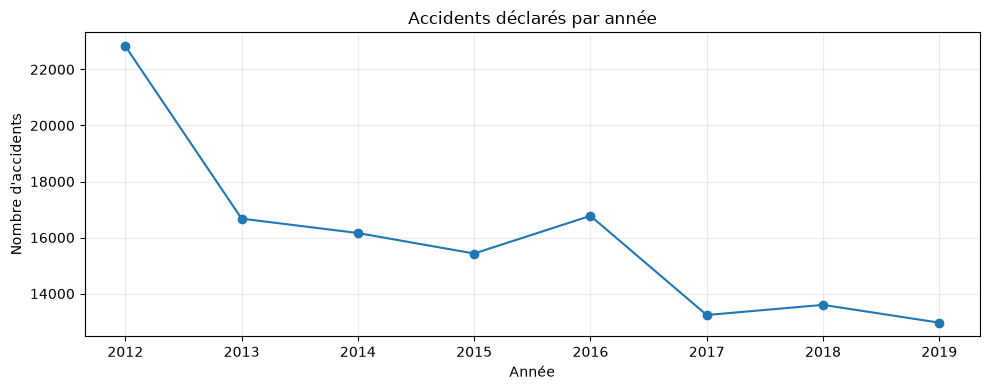

Entre 2012 et 2019, variation du nombre d'accidents : -43.2 %.


In [22]:
par_annee = (
    crash_df.filter(F.col("Year").between(2012, 2019))
    .groupBy("Year")
    .agg(
        F.count("REPORT_ID").alias("Accidents"),
        F.sum("Total Fats").alias("Deces"),
        F.sum(F.when(F.col("CSEF Severity") == "4: Fatal", 1).otherwise(0))
         .alias("Accidents_mortels"),
    )
    .withColumn("Part_mortels_pct", F.round(100 * F.col("Accidents_mortels") / F.col("Accidents"), 2))
    .orderBy("Year")
)
annee_pd = par_annee.toPandas()
display(annee_pd)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(annee_pd["Year"], annee_pd["Accidents"], marker="o")
ax.set(xlabel="Année", ylabel="Nombre d'accidents", title="Accidents déclarés par année")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

if len(annee_pd) > 1 and annee_pd.iloc[0]["Accidents"] > 0:
    debut, fin = annee_pd.iloc[0], annee_pd.iloc[-1]
    variation = 100 * (fin["Accidents"] / debut["Accidents"] - 1)
    print(f"Entre {int(debut['Year'])} et {int(fin['Year'])}, variation du nombre d'accidents : {variation:+.1f} %.")

### 6.2. Périodes les plus accidentogènes : jours de semaine et heures

La source ne révèle pas la date civile exacte ; nous exploitons `Day` (jour de semaine) et `Time` (heure). Un simple graphique de fréquences ne mesure pas un **risque individuel** : il faudrait le rapporter à l'exposition réelle au trafic.

/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


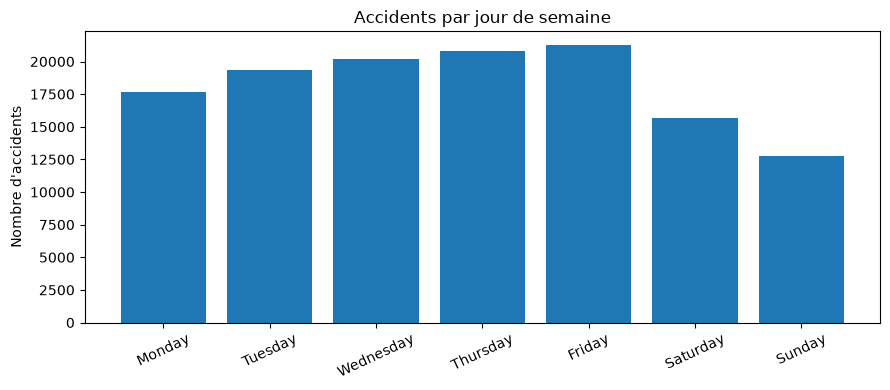

In [23]:
ordre_jours = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
par_jour = (
    crash_df.groupBy("Day").agg(F.count("REPORT_ID").alias("Accidents"))
    .toPandas().set_index("Day")
)
par_jour = par_jour.reindex(ordre_jours).fillna(0)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(par_jour.index, par_jour["Accidents"])
ax.set(title="Accidents par jour de semaine", ylabel="Nombre d'accidents")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


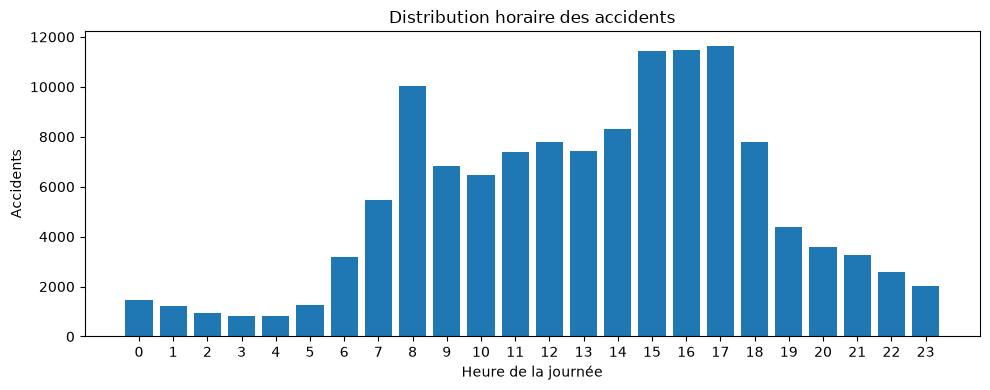

Horaires non reconnus : 0


In [24]:
# Certains CSV utilisent des horaires comme '01:20 am'.
# Une extraction régulière, avec correction du format 12 h, évite les erreurs.
heure_txt = F.lower(F.trim(F.col("Time")))
h12 = F.regexp_extract(heure_txt, r"^(\d{1,2}):\d{2}\s*([ap]m)$", 1)
suffixe = F.regexp_extract(heure_txt, r"^(\d{1,2}):\d{2}\s*([ap]m)$", 2)
h24 = F.regexp_extract(heure_txt, r"^(\d{1,2}):\d{2}$", 1)

crash_heures = crash_df.withColumn(
    "Heure_24",
    F.when(h12 != "", (h12.cast("int") % 12) + F.when(suffixe == "pm", 12).otherwise(0))
     .when(h24 != "", h24.cast("int"))
     .otherwise(F.lit(None).cast("int")),
)
crash_heures = crash_heures.withColumn(
    "Heure_24", F.when(F.col("Heure_24").between(0, 23), F.col("Heure_24"))
)
par_heure = (
    crash_heures.filter(F.col("Heure_24").isNotNull())
    .groupBy("Heure_24").count().orderBy("Heure_24").toPandas()
)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(par_heure["Heure_24"], par_heure["count"])
ax.set(xticks=list(range(24)), xlabel="Heure de la journée", ylabel="Accidents",
       title="Distribution horaire des accidents")
plt.tight_layout()
plt.show()
print("Horaires non reconnus :", crash_heures.filter(F.col("Heure_24").isNull()).count())

### 6.3. Gravité selon la luminosité et les conditions météo

Cette analyse ajoute une perspective contextuelle. Nous examinons la **proportion d'accidents mortels parmi les accidents enregistrés** pour chaque modalité ; les groupes rares sont identifiés pour éviter de surinterpréter un pourcentage instable.

In [25]:
def tableau_gravite_par(df, nom_colonne):
    return (
        df.groupBy(nom_colonne)
        .agg(
            F.count("REPORT_ID").alias("Accidents"),
            F.sum(F.when(F.col("CSEF Severity") == "4: Fatal", 1).otherwise(0))
             .alias("Accidents_mortels"),
        )
        .withColumn("Part_mortels_pct", F.round(
            100 * F.col("Accidents_mortels") / F.col("Accidents"), 2
        ))
        .orderBy(F.desc("Accidents"))
    )

print("Luminosité :")
tableau_gravite_par(crash_df, "DayNight").show(20, truncate=False)
print("Conditions météo :")
tableau_gravite_par(crash_df, "Weather Cond").show(20, truncate=False)

Luminosité :


+--------+---------+-----------------+----------------+
|DayNight|Accidents|Accidents_mortels|Part_mortels_pct|
+--------+---------+-----------------+----------------+
|Daylight|98724    |478              |0.48            |
|Night   |28948    |244              |0.84            |
+--------+---------+-----------------+----------------+

Conditions météo :


+------------+---------+-----------------+----------------+
|Weather Cond|Accidents|Accidents_mortels|Part_mortels_pct|
+------------+---------+-----------------+----------------+
|Not Raining |115956   |682              |0.59            |
|Raining     |11268    |35               |0.31            |
|Unknown     |448      |5                |1.12            |
+------------+---------+-----------------+----------------+



### 6.4. Profil d'âge des personnes renseignées dans `Units`

Nous répartissons les âges valides en tranches, pour voir quelles classes sont les plus présentes **parmi les unités documentées**. Il s'agit d'une **répartition des enregistrements**, pas d'un taux d'accident par habitant.

+-----------+-----+
|Tranche_age|count|
+-----------+-----+
|      00-17| 6562|
|      18-24|41256|
|      25-34|47730|
|      35-49|57156|
|      50-64|41543|
|        65+|23309|
+-----------+-----+



/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


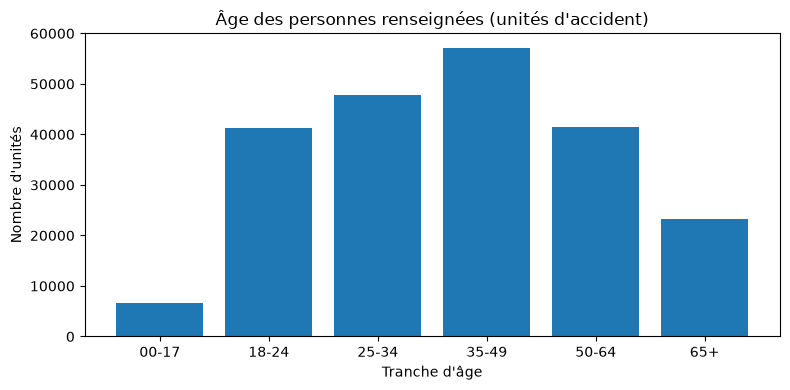

In [26]:
avec_ages = (
    units_df.filter(F.col("Age").between(1, 110))
    .withColumn(
        "Tranche_age",
        F.when(F.col("Age") < 18, "00-17")
         .when(F.col("Age") < 25, "18-24")
         .when(F.col("Age") < 35, "25-34")
         .when(F.col("Age") < 50, "35-49")
         .when(F.col("Age") < 65, "50-64")
         .otherwise("65+")
    )
)
par_age = avec_ages.groupBy("Tranche_age").count().orderBy("Tranche_age")
par_age.show()
page = par_age.toPandas()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(page["Tranche_age"], page["count"])
ax.set(title="Âge des personnes renseignées (unités d'accident)",
       ylabel="Nombre d'unités", xlabel="Tranche d'âge")
plt.tight_layout()
plt.show()

## 7. Comparaison expérimentale : RDD, DataFrame, Spark SQL

Nous réalisons **exactement le même calcul** : sommer les décès (`Total Fats`) par type de collision (`Crash Type`). L'objectif n'est pas de proclamer un gagnant universel : les mesures dépendent de l'ordinateur, de l'optimisation Spark, du cache disque, des partitions et de l'ordre des exécutions.

Chaque variante est exécutée une fois pour vérifier les résultats, puis chronométrée **trois fois**. Les temps incluent la collecte du **petit résultat agrégé**, et non le téléchargement de l'ensemble des données. Les plans d'exécution peuvent différer.

Validation : mêmes sommes de décès pour toutes les catégories.


,Approche,Médiane (s),Min (s),Max (s)
1,DataFrame,0.3608,0.3558,0.3919
2,Spark SQL,0.3864,0.3153,0.4063
0,RDD,0.6969,0.6187,0.7277


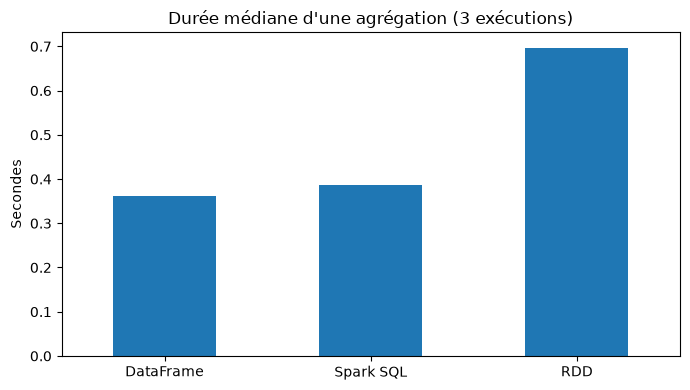

In [27]:
def calcul_rdd():
    return (
        crash_df.select("Crash Type", "Total Fats").rdd
        .map(lambda r: (r["Crash Type"], r["Total Fats"] or 0))
        .reduceByKey(lambda a, b: a + b).collect()
    )

def calcul_df():
    return crash_df.groupBy("Crash Type").agg(F.sum("Total Fats")).collect()

def calcul_sql():
    return spark.sql("""
        SELECT `Crash Type`, SUM(`Total Fats`) AS somme
        FROM crashes GROUP BY `Crash Type`
    """).collect()

fonctions = {"RDD": calcul_rdd, "DataFrame": calcul_df, "Spark SQL": calcul_sql}
resultats = {
    nom: {r[0]: int(r[1] or 0) for r in fonction()}
    for nom, fonction in fonctions.items()
}
assert resultats["RDD"] == resultats["DataFrame"] == resultats["Spark SQL"]
print("Validation : mêmes sommes de décès pour toutes les catégories.")

temps = {nom: [] for nom in fonctions}
for _ in range(3):
    for nom, fonction in fonctions.items():
        debut = perf_counter()
        fonction()  # action Spark -> exécution effective
        temps[nom].append(perf_counter() - debut)

mesures = pd.DataFrame([
    {"Approche": nom, "Médiane (s)": round(median(t), 4),
     "Min (s)": round(min(t), 4), "Max (s)": round(max(t), 4)}
    for nom, t in temps.items()
]).sort_values("Médiane (s)")
display(mesures)
ax = mesures.plot.bar(x="Approche", y="Médiane (s)", legend=False, figsize=(7, 4))
ax.set(title="Durée médiane d'une agrégation (3 exécutions)", ylabel="Secondes", xlabel="")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Discussion critique et limites

**Ce que nous avons amélioré par rapport à l'article original** :

1. **Lecture CSV fiable** : les lignes sont parsées par Spark plutôt qu'avec un `split(',')` sensible aux virgules dans les champs.
2. **Typage contrôlé** : les codes inconnus (`XXX`, `XXXX`) ne sont pas traités comme des nombres ; les données manquantes restent identifiables.
3. **Cardinalité des jointures** : le nombre de victimes appartient à l'accident, pas à chaque unité impliquée. L'utilisation d'identifiants distincts empêche le double comptage dans l'analyse des permis.
4. **Clarification des périmètres** : certains filtres de l'article sur les permis ne correspondent pas exactement à la question annoncée. Nos versions RDD, DataFrame et SQL appliquent les mêmes critères.
5. **Alcool/drogues** : `NULL` n'est pas synonyme de test négatif ; les indicateurs positifs peuvent se chevaucher.
6. **Mesures de performance** : les trois méthodes sont confrontées sur une requête identique, avec contrôle d'égalité des résultats.
7. **Nouveaux angles** : années, jours, heures, météo, luminosité et âge.

**Limites qui subsistent** :

- L'analyse porte sur des **accidents déclarés** en Australie-Méridionale, pas sur toutes les situations de conduite.
- Les dossiers téléchargés correspondent à un **instantané historique**, principalement 2012–2019 : ne pas extrapoler aux années actuelles.
- Les dates exactes ne sont pas disponibles dans la source telle que présentée par l'auteur. La combinaison `Year-Month-Day` n'est pas une date complète.
- L'absence de kilomètres parcourus, de trafic, de population exposée ou de données de dépistage exhaustives interdit de conclure à un risque individuel ou à une relation causale.
- Le dataset `Units` inclut différentes sortes d'unités, pas uniquement des conducteurs ; les âges décrivent les lignes **renseignées**.
- Trois mesures de temps sur un seul ordinateur constituent un **micro-benchmark illustratif**, pas une étude de performance exhaustive.
- La modalité météo `Unknown` ne contient que 448 accidents : sa proportion de fatalité élevée est instable et ne doit pas être interprétée comme un effet de la météo.
- Si les colonnes et les années diffèrent de l'instantané de l'auteur, des écarts de résultats sont attendus et doivent être explicités.

## 9. Conclusion

L'exécution porte sur **127 672 accidents** et **272 591 unités** couvrant les années 2012 à 2019. Les contrôles de qualité ne trouvent ni doublon de `REPORT_ID` dans `Crash`, ni unité ou accident sans correspondance. Les calculs RDD, DataFrame et Spark SQL donnent les mêmes résultats pour les requêtes comparées : 11 965 lignes pour la question sur Adélaïde et 2 053 victimes au total pour la question des unités sans permis.

**Reproduction et résultats principaux.** Les âges moyens obtenus sont de 40,80 ans pour les hommes et 40,08 ans pour les femmes, ce qui retrouve les valeurs de référence. Les accidents à Adélaïde avec plus de trois victimes sont au nombre de 6. Les types associés au plus grand nombre de décès sont `Hit Fixed Object` (245), `Head On` (136), `Hit Pedestrian` (109) et `Roll Over` (93). Les accidents mortels représentent 722 événements, soit 0,57 % du total ; ce nombre ne doit pas être confondu avec le nombre de personnes décédées.

**Évolution et analyses complémentaires.** Le nombre d'accidents enregistrés diminue de 22 829 en 2012 à 12 964 en 2019, soit -43,2 %. Le vendredi est le jour le plus représenté (21 249 accidents) et 17 h est l'heure la plus fréquente (11 642 accidents). La proportion d'accidents mortels est plus élevée la nuit (0,84 %) qu'en journée (0,48 %). Elle atteint 1,12 % pour la modalité météo `Unknown`, mais cet effectif est faible (448 accidents) ; il ne faut donc pas en tirer une conclusion causale. Les accidents avec alcool et drogues signalés simultanément présentent également une proportion de fatalité élevée (13,09 %), mais il s'agit d'une association descriptive et les groupes ne représentent pas nécessairement des tests exhaustifs.

**Comparaison des méthodes.** Sur cette machine et pour cette exécution, la médiane est de 0,3608 s avec l'API DataFrame, 0,3864 s avec Spark SQL et 0,6969 s avec RDD. Ces temps sont indicatifs : ils dépendent de l'ordre d'exécution, du cache, des partitions et de la configuration locale ; ils ne permettent pas de conclure qu'une API est toujours plus rapide.

**Conclusion générale.** L'étude montre l'intérêt de Spark pour charger et agréger plusieurs fichiers, mais l'interprétation dépend surtout de la qualité des données et de la granularité des tables. `Crash` décrit l'accident tandis que `Units` décrit les unités impliquées : une jointure naïve peut donc compter plusieurs fois les victimes. Enfin, les résultats décrivent des accidents déclarés en Australie-Méridionale et ne mesurent ni le risque individuel ni une relation causale.

### Sources

- Nain, R. (2 janvier 2021), [*Big Data Analysis of Road Crash Data using PySpark with PySpark Tutorial*](https://medium.com/rakesh-nain/big-data-analysis-of-road-crash-data-using-pyspark-with-pyspark-tutorial-c78ff2c35588).
- RakeshNain, [*Dépôt GitHub : notebooks et CSV*](https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial).
- Gouvernement d'Australie-Méridionale, [data.sa.gov.au](https://data.sa.gov.au/), documentation du jeu de données *Road Crash Data*.
- Apache Spark, [documentation PySpark](https://spark.apache.org/docs/latest/api/python/).